# Fast Food Marketing Campaign A\B Test

## Introduction

### Overview

This dataset includes A/B test results of a new fast food item sales to examine which marketing campaign was the most successful. The new item was introduced at different locations in several randomly selected markets.

Dataset includes:
- MarketID - a number for a randomly selected market (10 in total)
- MarketSize - size of market area by sales (small, medium, large)
- LocationID - store location unique ID (137 in total)
- AgeOfStore - age of store in years
- Promotion - promotion tested (3 in total)
- week - week when the promotions were run (4 in total)
- SalesInThousands - sales amount for a specific LocationID, Promotion, and week

Overview of the dataset also can be found in this [Looker Studio dashboard](https://lookerstudio.google.com/reporting/9e70f9ee-7e18-4d86-9014-0a0aaa7e78e7).

### Goal of the analysis

The goal of this analysis is to decide which marketing campaign was the most successful and lead to the most sales of the new item.

Questions to analyse:
1. Is there a statistically significant difference in mean sales across three promotions?
2. How can the promotions can be ranked from the most to the least successful?

### Target metric

Sales: total sales per location during 4 weeks of introducing the new item (by a specific promotion). The more sales there were, the more successful the campaign was in promoting the new product.

### Calculations

#### 1. Data overview

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
from fast_food_functions import histogram, histogram_compare_groups, histogram_with_ci

In [2]:
df_food = pd.read_csv("./WA_Marketing-Campaign.csv")
df_food.head()

,MarketID,MarketSize,LocationID,AgeOfStore,Promotion,week,SalesInThousands
0,1,Medium,1,4,3,1,33.73
1,1,Medium,1,4,3,2,35.67
2,1,Medium,1,4,3,3,29.03
3,1,Medium,1,4,3,4,39.25
4,1,Medium,2,5,2,1,27.81


In [3]:
df_food["sales"] = df_food["SalesInThousands"] * 1000

In [4]:
df_food.head()

,MarketID,MarketSize,LocationID,AgeOfStore,Promotion,week,SalesInThousands,sales
0,1,Medium,1,4,3,1,33.73,33730.0
1,1,Medium,1,4,3,2,35.67,35670.0
2,1,Medium,1,4,3,3,29.03,29030.0
3,1,Medium,1,4,3,4,39.25,39250.0
4,1,Medium,2,5,2,1,27.81,27810.0


In [5]:
print(f"Dataframe shape: {df_food.shape}")
print(f"\nMissing values:\n{df_food.isna().sum()}")
print(f"\nDuplicated entries: {df_food.duplicated().sum()}")

Dataframe shape: (548, 8)

Missing values:
MarketID            0
MarketSize          0
LocationID          0
AgeOfStore          0
Promotion           0
week                0
SalesInThousands    0
sales               0
dtype: int64

Duplicated entries: 0


In [6]:
print(f"Number of markets analysed: {df_food['MarketID'].nunique()}")
market_sizes = df_food["MarketSize"].unique()
print("Market types:", ", ".join(market_sizes))
print(f"Number of locations analysed: {df_food['LocationID'].nunique()}")
promotion_numbers = df_food["Promotion"].unique()
print("Promotions:", ", ".join([str(p) for p in promotion_numbers]))
print(f"Weeks of analysis: {df_food['week'].max()}")

Number of markets analysed: 10
Market types: Medium, Small, Large
Number of locations analysed: 137
Promotions: 3, 2, 1
Weeks of analysis: 4


In [7]:
age_stats = (
    r"$\bf{Store\ age\ statistics}$" + "\n"
    f"Count: {len(df_food['AgeOfStore'])}\n"
    f"Median: {df_food['AgeOfStore'].median():.2f}\n"
    f"Mean: {df_food['AgeOfStore'].mean():.2f}\n"
    f"Std: {df_food['AgeOfStore'].std():.2f}\n"
    f"Min: {df_food['AgeOfStore'].min():.0f}\n"
    f"Max: {df_food['AgeOfStore'].max():.0f}"
)

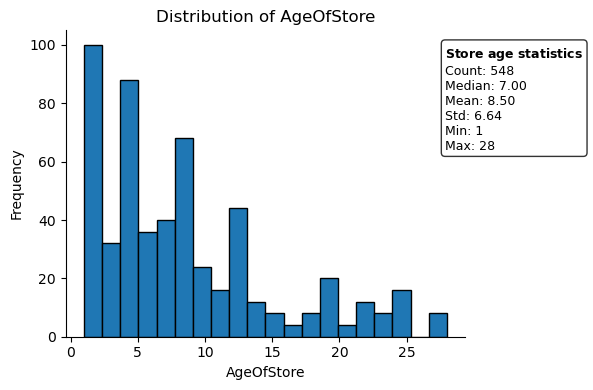

In [8]:
histogram(df=df_food, col="AgeOfStore", stats_text=age_stats)

Distribution of store age variable is exponential, with the mean value of 8,5 years.

In [9]:
sales_stats = (
    r"$\bf{Sales\ statistics}$" + "\n"
    f"Count: {len(df_food['sales'])}\n"
    f"Median: {df_food['sales'].median():.2f}\n"
    f"Mean: {df_food['sales'].mean():.2f}\n"
    f"Std: {df_food['sales'].std():.2f}\n"
    f"Min: {df_food['sales'].min():.0f}\n"
    f"Max: {df_food['sales'].max():.0f}"
)

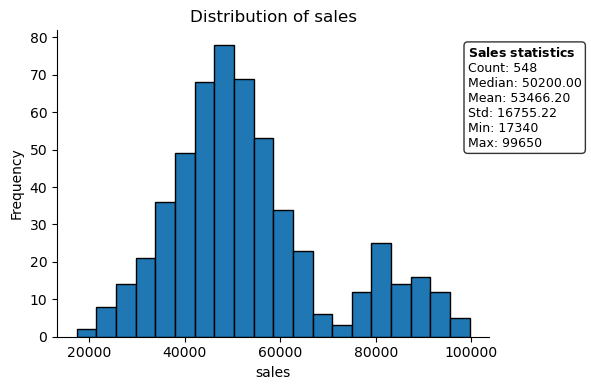

In [10]:
histogram(df=df_food, col="sales", stats_text=sales_stats)

The distribution of sales is bimodal, with the mean value of 53 466.

In [11]:
promotion_sales_text = {}

for i in range(1, 4):
    data = df_food[df_food["Promotion"] == i]["sales"]
    promotion_sales_text[i] = {
        "Count": len(data),
        "Median": data.median(),
        "Mean": round(data.mean(), 2),
        "Std": round(data.std(), 2),
        "Min": round(data.min()),
        "Max": round(data.max()),
    }

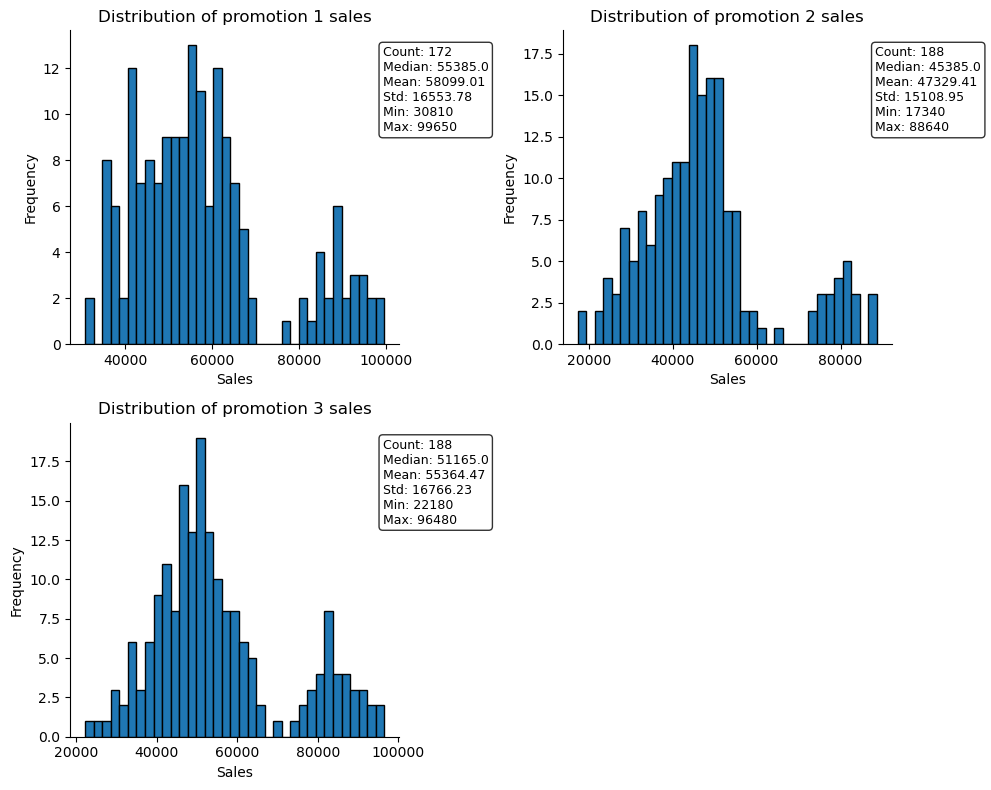

In [12]:
histogram_compare_groups(
    df=df_food,
    group="Promotion",
    metric="sales",
    figsize=(10, 8),
    bins=35,
    stats_text=promotion_sales_text,
)

Distributions of sales across three promotions are bimodal, group sizes are similar, mean values differ, with promotion 1 having the highest mean sales, promotion smaller sales amount and promotion 2 having the lowest mean sales.

#### 2. Statistical tests

#### 2.1 Promotion effectiveness

- H0: there is no statistically significant difference in mean sales across three promotions
- H1: there is a statistically significant difference in mean sales across three promotions

Variance homogeneity can be tested using Levene test:
- H₀: variances are homogeneous.
- H₁: variances are not homogeneous.

In [13]:
promotion_sales_text = {}

for i in range(1, 4):
    data = df_food[df_food["Promotion"] == i]["sales"]
    promotion_sales_text[i] = {
        "Count": len(data),
        "Median": data.median(),
        "Mean": round(data.mean(), 2),
        "Std": round(data.std(), 2),
        "Min": round(data.min()),
        "Max": round(data.max()),
    }

In [14]:
df_food_grouped_sales = df_food.groupby("LocationID").agg(
    {"sales": "sum", "Promotion": "first"}
)

In [15]:
promotions = {}

for i in range(1, 4):
    promotions[i] = df_food_grouped_sales[df_food_grouped_sales["Promotion"] == i][
        "sales"
    ]

In [16]:
statistic, p_value = stats.levene(*promotions.values())
statistic, p_value

(0.46816084440167766, 0.6271730417231256)

Since the p value is > 0.05, variances are homogenous.

I will use Kruskal Wallis t-test to compare the average sales accross the promotions, since the distribution was not normal, there are 3 groups to compare and the sample size is small (43-47 per group).
CIs will be computed analytically (using SciPy package) and using bootstrap.

In [17]:
scipy_ci = {}

for i in range(1, 4):
    data = promotions[i]
    mean = data.mean()
    std = data.std() / np.sqrt(len(data))
    scipy_ci[i] = stats.t.interval(
        confidence=0.95, df=len(data) - 1, loc=mean, scale=std
    )

In [18]:
bootstrap_ci = {}
for i in range(1, 4):
    data = promotions[i]
    result = stats.bootstrap(
        data=(data,),
        statistic=np.mean,
        confidence_level=0.95,
        method="percentile",
        random_state=51,
    )
    bootstrap_ci[i] = (result.confidence_interval.low, result.confidence_interval.high)

In [19]:
means = [promotions[i].mean() for i in range(1, 4)]
scipy_ci_list = [scipy_ci[i] for i in range(1, 4)]
bootstrap_ci_list = [bootstrap_ci[i] for i in range(1, 4)]

In [ ]:
scipy_lower_errors = []
scipy_upper_errors = []

for mean, ci in zip(means, scipy_ci_list):
    lower_error = mean - ci[0]
    scipy_lower_errors.append(lower_error)
    upper_error = ci[1] - mean
    scipy_upper_errors.append(upper_error)

In [21]:
bootstrap_lower_errors = []
bootstrap_upper_errors = []

for mean, ci in zip(means, bootstrap_ci_list):
    lower_error = mean - ci[0]
    bootstrap_lower_errors.append(lower_error)
    upper_error = ci[1] - mean
    bootstrap_upper_errors.append(upper_error)

In [22]:
statistic, p_value = stats.kruskal(*promotions.values())
n = sum(len(data) for data in promotions.values())
epsilon_squared = statistic / (n - 1)

In [23]:
kruskal_wallis_test_text = (
    r"$\bf{Kruskal\ Wallis\ test}$"
    + "\n"
    + f"H-statistic: {statistic:.4f}\n"
    + f"p-value: {p_value:.4f}\n"
    + f"Epsilon-squared (effect size): {epsilon_squared:.3f}"
)

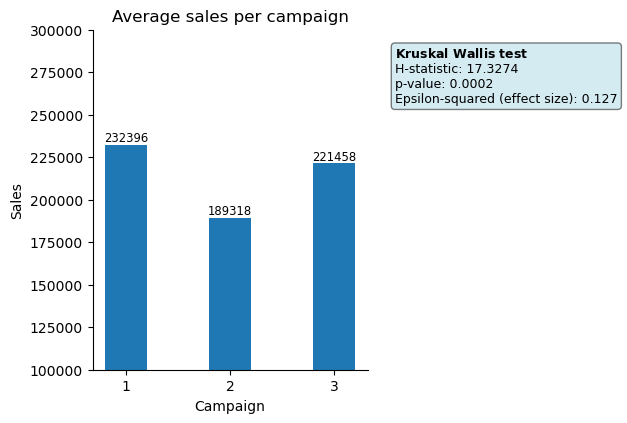

In [27]:
histogram_with_ci(
    means,
    title="Average sales per campaign",
    ylabel="Sales",
    xlabel="Campaign",
    labels=[1, 2, 3],
    stats_text=kruskal_wallis_test_text,
    figsize=(5,4)
)

In [41]:
table_data = []
for key in scipy_ci.keys():
    table_data.append({
    'Promotion': f'Promotion {key}',
    'Scipy CI': f"{scipy_ci[key][0]:.2f} - {scipy_ci[key][1]:.2f}",
    'Bootstrap CI': f"{bootstrap_ci[key][0]:.2f} - {bootstrap_ci[key][1]:.2f}"
})

df = pd.DataFrame(table_data)
pd.options.display.float_format = '{:.2f}'.format
df

,Promotion,Scipy CI,Bootstrap CI
0,Promotion 1,212665.01 - 252127.08,214373.57 - 252004.65
1,Promotion 2,172291.63 - 206343.69,173746.38 - 206777.67
2,Promotion 3,202215.94 - 240699.81,203620.14 - 240838.32


- We see statistically significant difference between the campaigns (p < 0.05), with medium effect size (0.127).
- CIs calculated analytically and using bootstrap are similar, which shows that the parametric asumptions for this data were reasonable.
- However, the CIs are wide due to a small sample size, which shows lack of statistical precision in the analysis.

#### 2.2 Post-hoc analysis - the most successfull promotion
- H0: there is no difference in mean sales between any pair of promotions
- H1: at least one pair of promotions has significantly different mean sales

Using a Bonferroni correction because of the multiple testing (p value is 0.05 / 3 = 0.017)

In [44]:
post_hoc_test_text = (
    r"$\bf{Post-hoc\ test}$"
    + "\n"
    + f"Campaign 1 vs 2: {'Differs' if stats.mannwhitneyu(promotions[1], promotions[2])[1] < 0.017 else 'Does not differ'}\n"
    + f"Campaign 1 vs 3: {'Differs' if stats.mannwhitneyu(promotions[1], promotions[3])[1] < 0.017 else 'Does not differ'}\n"
    + f"Campaign 2 vs 3: {'Differs' if stats.mannwhitneyu(promotions[3], promotions[2])[1] < 0.017 else 'Does not differ'}"
)

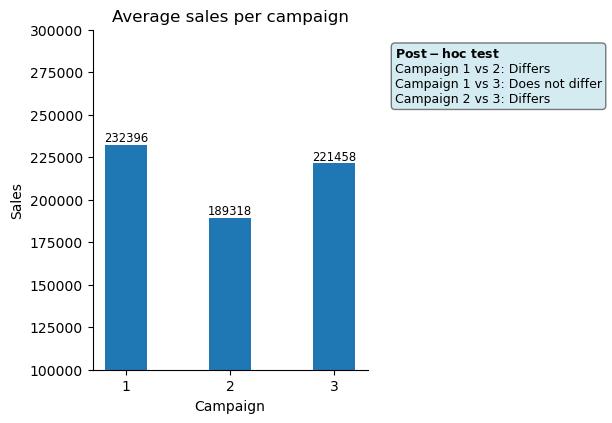

In [45]:
histogram_with_ci(
    means,
    title="Average sales per campaign",
    ylabel="Sales",
    xlabel="Campaign",
    labels=[1, 2, 3],
    stats_text=post_hoc_test_text,
    figsize=(5,4)
)

- Looking at the means, the promotion 1 is the best perfoming. Promotion 2 is the worst performing.
- Post-hoc test results show that there are significant differences between promotion 2 and the rest.

### Decision

Promotion 1 and 3 are the best performing and statistically similar - if we have to choose one, it's better to choose the cheaper one, since the results would be similar.

### Conclusions

Dataset about a new fast food item sales was analysed. This dataset included:
- 10 randomly selected markets
- 137 store locations
- 3 tested campaigns
- 4 weeks of sales
- sales amount

There were statistically significant differences in sales across the campaigns, with campaign 1 and 2 performing the best. 

For the best results, either campaign 1 or 2 can be chosen, the choice can also depend on the costs of these campaigns, which were not included in the dataset analyzed.

However, we should keep in mind the small sample sizes, which lead to lower statistical precision. In order to achieve more precise results, a larger dataset is needed.